# Preliminary Phase 1 on Kaggle: trajectory balance (GFlowNet) against GRPO

This runs the Phase 1 comparison at a smaller scale, inside one free Kaggle session. Qwen3-1.7B learns to fix a wrong step 2 in a GSM8K answer, and half of each group of answers continues after " Wait".

- `PAIR = "main"` runs T5 (trajectory balance) against T4 (GRPO), both learning from the nudged answers. Run this first.
- `PAIR = "own"` runs T3 against T2, on the model's own answers only. Run it in a second session.

The two runs share the session, one on each T4. If Kaggle's 12-hour limit would cut a run off, the run stops early, evaluates and saves. `docs/kaggle-prelim.md` lists what is smaller than in Phase 1.

**Settings:** Accelerator **GPU T4 x2**, Internet **on**.

**Run it with Save Version, then Save & Run All (Commit)**, so it keeps running after you close the browser. When it finishes, download `bundles/prelim-*.tar.gz` from the version's Output tab.

In [1]:
PAIR = "main"   # "main": T5 against T4, the first session. "own": T3 against T2, the second session.
REPO_URL = "https://github.com/amitkov-sudo/grpo-vs-gfn-self-correction.git"

!test -d repo || git clone -q $REPO_URL repo
%cd repo
!git pull -q && git log -1 --format="commit %h, %cd"

/kaggle/working/repo
commit 21cc10e, Wed Nov 25 00:07:11 2026 -0800


In [2]:
# Installs the requirements, runs the offline checks, then trains both runs side by side (up to 11.5 hours).
!PAIR=$PAIR bash scripts/kaggle_prelim.sh

GPUs: ['Tesla T4', 'Tesla T4']
CPU checks: offline tests and the smoke run
...........ss......................................................      [100%]
65 passed, 2 skipped in 23.92s
Reconstructing (incomplete total...): |            |  0.00B /  0.00B            

Fetching 12 files:   0%|                                 | 0/12 [00:00<?, ?it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.

Reconstructing (incomplete total...):   0%|        |  0.00B / 11.3kB            

Fetching 12 files:   8%|██                       | 1/12 [00:00<00:01,  8.44it/s]
Reconstructing (incomplete total...):  45%|███▌    | 11.3kB / 25.3kB            
Reconstructing (incomplete total...):  42%|███▍    | 11.3kB / 26.9kB            
Reconstructing (incomplete total...):   2%|▏       | 26.9kB / 1.70MB            
Reconstructing (incomplete total...):   2%|▏       | 26.9kB / 1.70MB            
Reconstructing (incomplete

## Final evaluations

| run | condition | step | fix rate | false alarms | clean right | fix pass@4 | fix vote@4 | sampled fix rate | sampled false alarms |
|---|---|---|---|---|---|---|---|---|---|
| prelim-T4-s0 | T4 | 60 | 47/60 | 36/60 | 49/60 | 90.0% | 83.3% | 76.7% | 46.2% |
| prelim-T5-s0 | T5 | 60 | 2/60 | 0/60 | 48/60 | 10.0% | 6.7% | 5.4% | 0.0% |

Fix rate and clean right use greedy decoding on the 60 GSM8K-SC test problems. A false alarm is a
correct start whose continuation opens by calling the step wrong. The sampled columns use the
sampled answers per start at temperature 1.

## Error moved to step 2, 3 or 4

| run | condition | step | step 2: fixed | step 2: vote@4 | step 2: false alarms | step 3: fixed | step 3: vote@4 | step 3: false alarms | step 4: fixed | step 4: vote@4 | step 4: false alarms |
|---|---|---|---|---|---|---|---|---|---|---|---|
| prelim-T4-s0 | T4 | 0 | 1/20 | 5.0% | 0/20 | 3/20 | 15.0% | 0/20 | 2/20 | 15.0% | 0/20 |
| prelim-T4-s0 | T4 | 60 | 13/20 | 70.0% | 12/20 | 12/20 | 75.0% | 11/20 | 15/20 | 80.0% | 9/20 |
| prelim-T5-s0 | T5 | 0 | 1/20 | 5.0% | 0/20 | 3/20 | 15.0% | 0/20 | 2/20 | 15.0% | 0/20 |
| prelim-T5-s0 | T5 | 60 | 1/20 | 15.0% | 0/20 | 3/20 | 15.0% | 0/20 | 2/20 | 15.0% | 0/20 |

Matched GSM8K test problems, each with its error at every step listed; evaluated at step 0 and at
the end of training. Training only sees errors at step 2.

## Openings that approve the written step

| run | condition | step | approves a wrong step | approves a correct step |
|---|---|---|---|---|
| prelim-T4-s0 | T4 | 0 | 0/60 | 0/60 |
| prelim-T4-s0 | T4 | 20 | 0/60 | 0/60 |
| prelim-T4-s0 | T4 | 40 | 0/60 | 0/60 |
| prelim-T4-s0 | T4 | 60 | 0/60 | 0/60 |
| prelim-T5-s0 | T5 | 0 | 0/60 | 0/60 |
| prelim-T5-s0 | T5 | 20 | 0/60 | 0/60 |
| prelim-T5-s0 | T5 | 40 | 0/60 | 0/60 |
| prelim-T5-s0 | T5 | 60 | 0/60 | 0/60 |

A continuation approves when it opens with words like "That step is correct" or "Yes". In the
attacker-replies test this shows how far the attacker's phrase spread into the model's own answers.

## Every evaluation

| run | condition | step | fix rate | false alarms | clean right | fix pass@4 | fix vote@4 | sampled fix rate | sampled false alarms |
|---|---|---|---|---|---|---|---|---|---|
| prelim-T4-s0 | T4 | 0 | 1/60 | 0/60 | 49/60 | 10.0% | 5.0% | 5.4% | 0.0% |
| prelim-T4-s0 | T4 | 20 | 45/60 | 13/60 | 51/60 | 86.7% | 68.3% | 62.9% | 21.7% |
| prelim-T4-s0 | T4 | 40 | 48/60 | 46/60 | 48/60 | 90.0% | 83.3% | 78.3% | 65.0% |
| prelim-T4-s0 | T4 | 60 | 47/60 | 36/60 | 49/60 | 90.0% | 83.3% | 76.7% | 46.2% |
| prelim-T5-s0 | T5 | 0 | 1/60 | 0/60 | 49/60 | 10.0% | 5.0% | 5.4% | 0.0% |
| prelim-T5-s0 | T5 | 20 | 5/60 | 0/60 | 48/60 | 15.0% | 5.0% | 6.2% | 1.7% |
| prelim-T5-s0 | T5 | 40 | 2/60 | 0/60 | 49/60 | 16.7% | 10.0% | 7.5% | 0.4% |
| prelim-T5-s0 | T5 | 60 | 2/60 | 0/60 | 48/60 | 10.0% | 6.7% | 5.4% | 0.0% |

## Progress

| run | condition | steps done | last log-ratio | poisoned starts fixed, last 10 steps | mean step time | finished |
|---|---|---|---|---|---|---|
| prelim-T4-s0 | T4 | 60/60 | 49.07 |  | 268 s | yes |
| prelim-T5-s0 | T5 | 60/60 | 1.28 |  | 252 s | yes |

Queue: 2 of 2 runs finished.
Time left for the queue: about 0 h 0 min (estimate from the mean step and evaluation times so far).


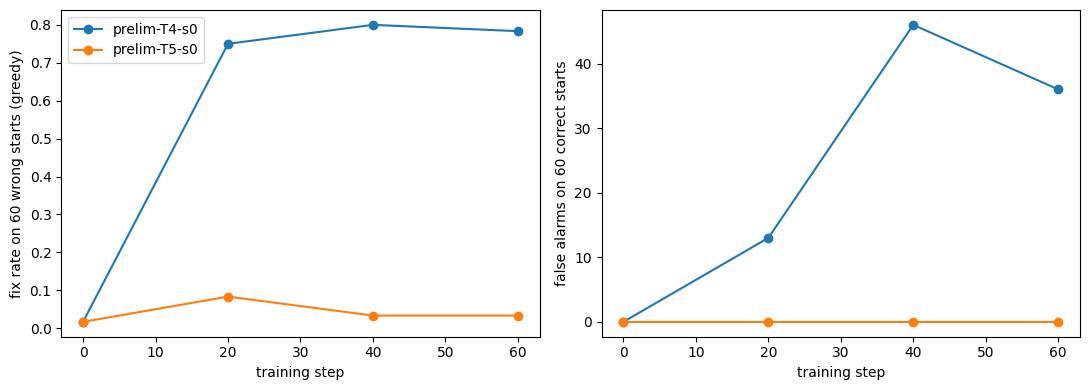

In [3]:
import glob, json, os
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

display(Markdown(open("outputs/prelim-summary.md").read()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for path in sorted(glob.glob("outputs/prelim-*/log.jsonl")):
    evals = [r["eval"] for r in map(json.loads, open(path)) if "eval" in r]
    run = os.path.basename(os.path.dirname(path))
    steps = [e["step"] for e in evals]
    ax1.plot(steps, [e["fix_rate"] for e in evals], marker="o", label=run)
    ax2.plot(steps, [e["false_alarms"] for e in evals], marker="o", label=run)
ax1.set(xlabel="training step", ylabel="fix rate on 60 wrong starts (greedy)")
ax2.set(xlabel="training step", ylabel="false alarms on 60 correct starts")
ax1.legend()
plt.tight_layout()
plt.show()